# Lab: Linear Regression Prediction

**Group 3: MosquitoSentinel**

**Members and contributions:**
- Credo, Ma. Azumi: [what they did, e.g. Part 1 linear regression, Tasks 1 to 6]
- Elamparo, Renz Herald: [e.g. Tasks 7 to 9, convolution, ReLU, pooling]
- Pagunsan, Mery France: [e.g. Tasks 10 and 11, Reflection, documentation]

# Lab: CNN Building Blocks

**Members and contributions:**
- Sarmiento, Mary Hyacinth: [Task 7 to 11]
- Resco, Ella Mae: [Reflection, documentation]


## Task 7: Load and prepare the image

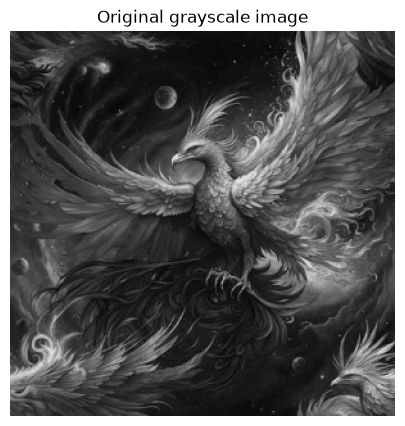

Shape: (300, 300, 1) dtype: <dtype: 'uint8'>


In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

raw_image = tf.io.read_file("image.jpg")
gray_image = tf.io.decode_jpeg(raw_image, channels=1)
gray_image = tf.image.resize(gray_image, [300, 300])
gray_image = tf.cast(gray_image, tf.uint8)   # back to uint8 so the 0-1 conversion works

plt.figure(figsize=(5, 5))
plt.imshow(tf.squeeze(gray_image).numpy(), cmap="gray", vmin=0, vmax=255)
plt.title("Original grayscale image")
plt.axis("off")
plt.show()

print("Shape:", gray_image.shape, "dtype:", gray_image.dtype)

In [2]:
image_batch = tf.image.convert_image_dtype(gray_image, tf.float32)  
image_batch = tf.expand_dims(image_batch, axis=0)
print("New shape:", image_batch.shape, "dtype:", image_batch.dtype)
print("Min:", float(tf.reduce_min(image_batch)), "Max:", float(tf.reduce_max(image_batch)))

New shape: (1, 300, 300, 1) dtype: <dtype: 'float32'>
Min: 0.007843137718737125 Max: 0.960784375667572


## Task 8: Convolution

Kernel shape: (3, 3, 1, 1) dtype: <dtype: 'float32'>
Convolution output shape: (1, 300, 300, 1)


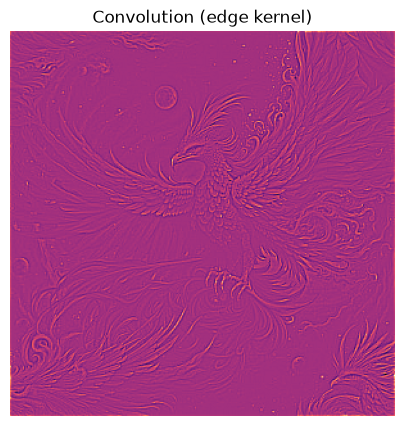

In [3]:
kernel = tf.constant([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
])
kernel = tf.reshape(kernel, [3, 3, 1, 1])
kernel = tf.cast(kernel, tf.float32)
print("Kernel shape:", kernel.shape, "dtype:", kernel.dtype)

convolution_output = tf.nn.conv2d(
    input=image_batch,
    filters=kernel,
    strides=1,
    padding="SAME"
)
print("Convolution output shape:", convolution_output.shape)

plt.figure(figsize=(5, 5))
plt.imshow(tf.squeeze(convolution_output).numpy(), cmap="magma")
plt.title("Convolution (edge kernel)")
plt.axis("off")
plt.show()

**Q8.1: What is the sum of the kernel's weights, and what response do you expect on a perfectly flat region?**

The weights sum to 8 + (8 × -1) = 0. On a perfectly flat region, every pixel under the kernel has the same value, so the center term (8 × value) is exactly cancelled by the eight neighbors (-8 × value) and the output is 0. This is why the kernel only responds where brightness changes, such as at edges.

**Q8.2: What do you notice at the image border, and what causes it?**

A thin bright outline appears along the border of the output. It is caused by padding="SAME", which adds zeros around the image so the 3×3 kernel can be centered on edge pixels. Those fake zero neighbors make edge pixels look much brighter than their surroundings, so the kernel reports an edge that is not really in the picture.

## Task 9: ReLU and max pooling

Min before ReLU: -3.1058826446533203
Min after ReLU:  0.0
Pooling output shape: (1, 150, 150, 1)
Values before pooling: 90000
Values after pooling:  22500
Reduction factor: 4.0


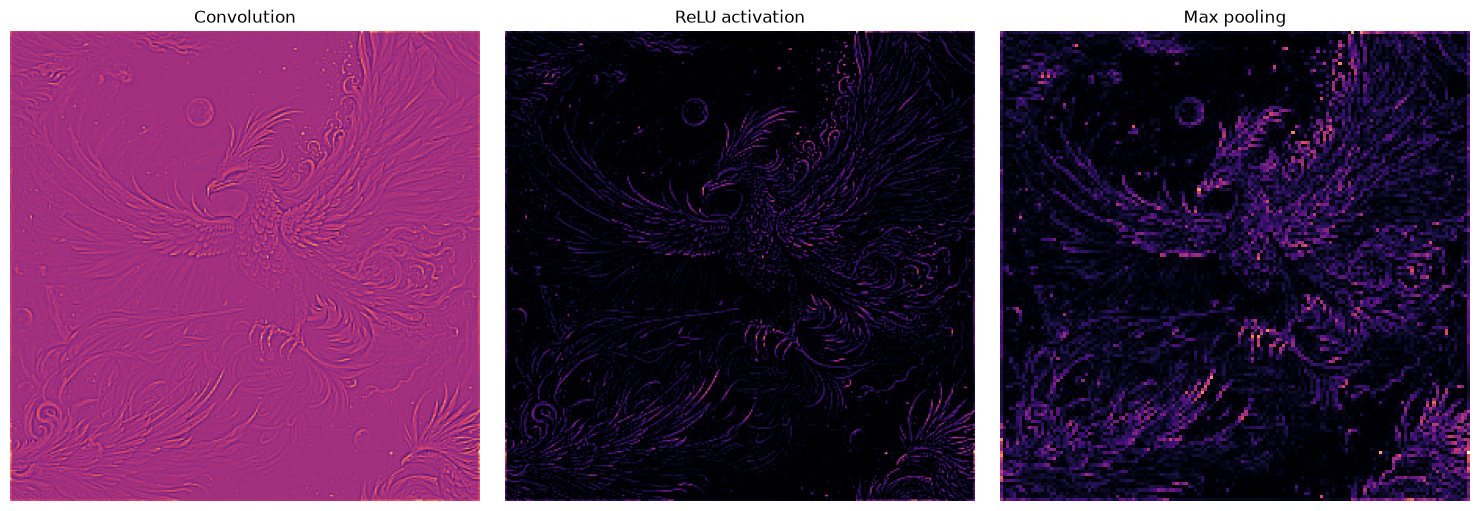

In [4]:
relu_output = tf.nn.relu(convolution_output)
print("Min before ReLU:", float(tf.reduce_min(convolution_output)))
print("Min after ReLU: ", float(tf.reduce_min(relu_output)))

pooling_output = tf.nn.pool(
    input=relu_output,
    window_shape=(2, 2),
    pooling_type="MAX",
    strides=(2, 2),
    padding="SAME"
)
print("Pooling output shape:", pooling_output.shape)

values_before = int(tf.size(relu_output))
values_after = int(tf.size(pooling_output))
print("Values before pooling:", values_before)
print("Values after pooling: ", values_after)
print("Reduction factor:", values_before / values_after)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, data, title in zip(
    axes,
    [convolution_output, relu_output, pooling_output],
    ["Convolution", "ReLU activation", "Max pooling"],
):
    ax.imshow(tf.squeeze(data).numpy(), cmap="magma")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

**Q9.1: What did ReLU change in the data?**

ReLU replaced every negative value with 0 and left positive values unchanged. The minimum value went from -3.0977 before ReLU to 0.0 after, while the shape stayed the same. This keeps only the positive responses of the edge kernel, and it adds the non-linearity that CNNs need.

**Q9.2: By what factor did pooling reduce the number of values?**

Pooling reduced the number of values by a factor of 4, from 90,000 (300 × 300) to 22,500 (150 × 150). Each 2×2 window of 4 values is replaced by its single maximum.

**Q9.3: Name one benefit and one cost of pooling.**

One benefit is that it reduces computation and memory for later layers, and it makes the result a little more tolerant to small shifts of a feature. One cost is that it discards detail, since three of every four values are thrown away and the exact position of a feature inside each window is lost.

## Task 10: Kernel experiments

**Predictions (written before running the figure):**
- Sobel X: should highlight vertical edges, because it compares the left and right neighbors of each pixel.
- Sobel Y: should highlight horizontal edges, because it compares the top and bottom neighbors.
- Box blur: should look like a softer version of the original, because it averages each pixel with its 8 neighbors.
- Sharpen: should look like the original with stronger contrast at edges, because it boosts the center pixel and subtracts its neighbors.

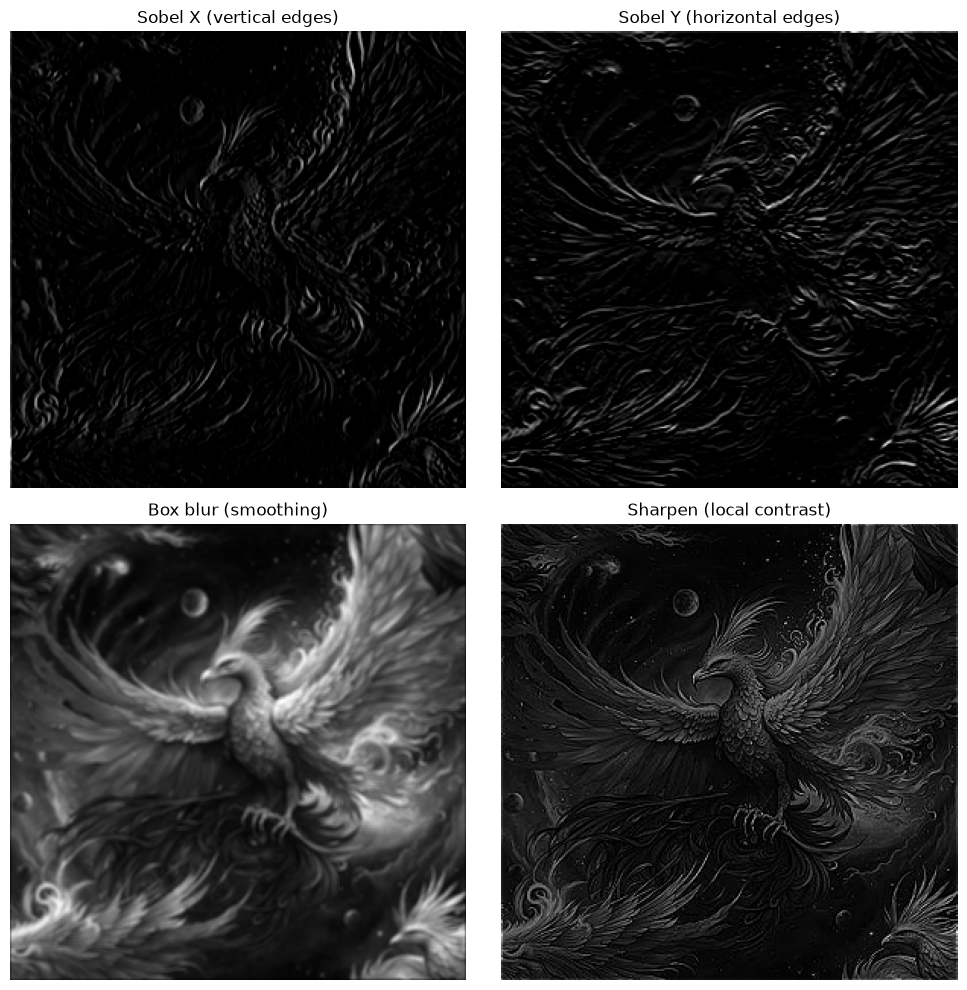

Task 8 edge: sum of weights = 0.00
Sobel X: sum of weights = 0.00
Sobel Y: sum of weights = 0.00
Box blur: sum of weights = 1.00
Sharpen: sum of weights = 1.00


In [7]:
def apply_kernel(k):
    k = tf.constant(k, dtype=tf.float32)
    k = tf.reshape(k, [3, 3, 1, 1])
    out = tf.nn.conv2d(image_batch, k, strides=1, padding="SAME")
    return tf.nn.relu(out)

sobel_x = [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
sobel_y = [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]
box_blur = (tf.constant([[1, 1, 1], [1, 1, 1], [1, 1, 1]], dtype=tf.float32) / 9.0).numpy()
sharpen = [[0, -1, 0], [-1, 5, -1], [0, -1, 0]]

kernels = {
    "Sobel X (vertical edges)": sobel_x,
    "Sobel Y (horizontal edges)": sobel_y,
    "Box blur (smoothing)": box_blur,
    "Sharpen (local contrast)": sharpen,
}

fig, axes = plt.subplots(2, 2, figsize=(10, 10))
for ax, (name, k) in zip(axes.flatten(), kernels.items()):
    ax.imshow(tf.squeeze(apply_kernel(k)).numpy(), cmap="gray")
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

all_kernels = {
    "Task 8 edge": [[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]],
    "Sobel X": sobel_x,
    "Sobel Y": sobel_y,
    "Box blur": box_blur,
    "Sharpen": sharpen,
}
for name, k in all_kernels.items():
    print(f"{name}: sum of weights = {float(tf.reduce_sum(tf.constant(k, dtype=tf.float32))):.2f}")

**Comparison with predictions:**
The box blur and sharpen results matched my predictions. [Say whether Sobel X and Sobel Y matched yours. For example: the phoenix has many curved and diagonal feather strokes, so Sobel Y showed more detail than I expected.]

**Q10.1: Which kernel highlights vertical lines most clearly?**

Sobel X highlights vertical lines most clearly. In my figure, [describe one specific vertical feature you see in the Sobel X panel, e.g. the side edges of the planet or a vertical feather stroke], while the Sobel Y panel responds more to horizontal features. This is because Sobel X compares the left and right neighbors of each pixel, so a vertical edge produces a large response.

**Q10.2: Sum of weights and what it does on flat regions**

Sums: Task 8 edge kernel = 0, Sobel X = 0, Sobel Y = 0, Box blur = 1, Sharpen = 1. On a flat region every pixel under the kernel has the same value, so the output is that value times the sum of the weights. Kernels that sum to 0 therefore output 0 on flat regions (they appear black and only respond to changes), and kernels that sum to 1 preserve the original brightness of flat regions.

**Q10.3: Why does the blurred result resemble the original but look softer?**

The box blur replaces each pixel with the average of itself and its 8 neighbors. Because the weights sum to 1, overall brightness and large shapes are preserved, so it resembles the original. Averaging mixes neighboring values, which smooths out sharp transitions and fine detail, so it looks softer.

## Task 11: Padding, stride, and pooling shapes

In [6]:
edge_kernel = tf.reshape(
    tf.constant([[-1, -1, -1], [-1, 8, -1], [-1, -1, -1]], dtype=tf.float32),
    [3, 3, 1, 1]
)

r1 = tf.nn.conv2d(image_batch, edge_kernel, strides=1, padding="SAME")
r2 = tf.nn.conv2d(image_batch, edge_kernel, strides=1, padding="VALID")
r3 = tf.nn.conv2d(image_batch, edge_kernel, strides=2, padding="SAME")
r4 = tf.nn.pool(r1, window_shape=(2, 2), pooling_type="MAX", strides=(2, 2), padding="SAME")
r5 = tf.nn.pool(r1, window_shape=(4, 4), pooling_type="MAX", strides=(4, 4), padding="SAME")
r6 = tf.nn.pool(r2, window_shape=(2, 2), pooling_type="MAX", strides=(2, 2), padding="SAME")

rows = [
    ("1 Conv s1 SAME", r1),
    ("2 Conv s1 VALID", r2),
    ("3 Conv s2 SAME", r3),
    ("4 Pool 2x2 s2 SAME", r4),
    ("5 Pool 4x4 s4 SAME", r5),
    ("6 VALID conv + pool 2x2", r6),
]
for label, r in rows:
    print(label, "->", r.shape)

1 Conv s1 SAME -> (1, 300, 300, 1)
2 Conv s1 VALID -> (1, 298, 298, 1)
3 Conv s2 SAME -> (1, 150, 150, 1)
4 Pool 2x2 s2 SAME -> (1, 150, 150, 1)
5 Pool 4x4 s4 SAME -> (1, 75, 75, 1)
6 VALID conv + pool 2x2 -> (1, 149, 149, 1)


Input: (1, 300, 300, 1). Kernel: Task 8 edge kernel (3x3).

| # | Operation | Predicted shape | Measured shape |
|---|-----------|-----------------|----------------|
| 1 | Conv, stride 1, SAME | (1, 300, 300, 1) | (1, 300, 300, 1) |
| 2 | Conv, stride 1, VALID | (1, 298, 298, 1) | (1, 298, 298, 1) |
| 3 | Conv, stride 2, SAME | (1, 150, 150, 1) | (1, 150, 150, 1) |
| 4 | Max pool 2x2, stride 2, SAME | (1, 150, 150, 1) | (1, 150, 150, 1) |
| 5 | Max pool 4x4, stride 4, SAME | (1, 75, 75, 1) | (1, 75, 75, 1) |
| 6 | Conv VALID, then max pool 2x2, stride 2, SAME | (1, 149, 149, 1) | (1, 149, 149, 1) |

**Q11.1: Which setting keeps the image size unchanged after convolution?**

Padding SAME with stride 1 keeps the size unchanged (300 stays 300). SAME pads the border with zeros so the kernel can be centered on every pixel, and stride 1 moves it one pixel at a time, giving one output per input pixel. With stride 2, SAME would still halve the size.

**Q11.2: Give one reason someone might choose VALID instead of SAME.**

VALID uses only real pixels and adds no padding, so the output has no artifacts from fake zero borders (like the bright frame we saw in Task 8). The cost is that the image shrinks a little with each layer.

## Reflection